In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

print("WasteWise environment is ready!")

WasteWise environment is ready!


In [2]:
from datasets import load_dataset

dataset = load_dataset("thomasavare/waste-classification-v2")
print(dataset)

README.md:   0%|          | 0.00/1.46k [00:00<?, ?B/s]

train2.csv:   0%|          | 0.00/1.48M [00:00<?, ?B/s]

test2.csv:   0%|          | 0.00/368k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/21528 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5382 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'Phrase', 'Class', 'Class_index'],
        num_rows: 21528
    })
    test: Dataset({
        features: ['Unnamed: 0', 'Phrase', 'Class', 'Class_index'],
        num_rows: 5382
    })
})


In [3]:
# Display available splits
print("Available splits:", dataset.keys())

# Display number of rows in each split
for split in dataset.keys():
    print(split, ":", len(dataset[split]), "rows")

# Inspect column names
first_split = list(dataset.keys())[0]

print("\nColumns:")
print(dataset[first_split].column_names)

# Display first five records
print("\nSample records:")
display(
    pd.DataFrame(dataset[first_split][:5])
)

Available splits: dict_keys(['train', 'test'])
train : 21528 rows
test : 5382 rows

Columns:
['Unnamed: 0', 'Phrase', 'Class', 'Class_index']

Sample records:


,Unnamed: 0,Phrase,Class,Class_index
0,17110,"I have this apple phone charger to throw, wher...",PHONE CHARGER,26.0
1,20094,Should I recycle a disposable cup ?,PLASTIC CUP,32.0
2,5638,"I have this surgical masks, where should I thr...",FACE MASK,10.0
3,1915,Should I recycle this cigarette remains ?,CIGARETTE BUTT,3.0
4,25050,I have a milk brick,TETRAPACK,45.0


In [4]:
# Find the label column
print(dataset[first_split].features)

{'Unnamed: 0': Value('int64'), 'Phrase': Value('string'), 'Class': Value('string'), 'Class_index': Value('float64')}


In [5]:
# Convert Hugging Face splits into Pandas DataFrames

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())

Training shape: (21528, 4)
Testing shape: (5382, 4)


,Unnamed: 0,Phrase,Class,Class_index
0,17110,"I have this apple phone charger to throw, wher...",PHONE CHARGER,26.0
1,20094,Should I recycle a disposable cup ?,PLASTIC CUP,32.0
2,5638,"I have this surgical masks, where should I thr...",FACE MASK,10.0
3,1915,Should I recycle this cigarette remains ?,CIGARETTE BUTT,3.0
4,25050,I have a milk brick,TETRAPACK,45.0


In [6]:
# Count unique categories
print("Number of unique classes:", train_df["Class"].nunique())

# Display all categories
classes = sorted(train_df["Class"].unique())

print("\nWaste categories:")
for category in classes:
    print(category)

Number of unique classes: 50

Waste categories:
ALUMINIUM CAN
ALUMINIUM SHEET
ALUMINIUM TRAY
CIGARETTE BUTT
CIGARETTE PACK
COMPOSTABLE PACKAGING
CONDIMENT PACKETS
COVID TEST
CRUMBLED TISSUE
CYLINDRICAL BATTERY
FACE MASK
GLASS BOTTLE
GLASS JAR
LAPTOP CHARGER
MEDS BLISTER
METAL CAP
MIXED PAPER-PLASTIC PACKAGING
ORGANIC SCRAPS
PAPER BOWL
PAPER CUP
PAPER FOOD PACKAGING
PAPER MAGASINE
PAPER PACKAGING
PAPER PLATE
PAPER SHEET
PAPER SUGAR BAG
PAPER TRAY
PHONE CHARGER
PIZZA BOX
PLASTIC BAG
PLASTIC BOTTLE
PLASTIC BOWL
PLASTIC CAP
PLASTIC CUP
PLASTIC CUTLERY
PLASTIC DISH
PLASTIC GLOVES
PLASTIC PACKAGING
PLASTIC SNACK PACKAGING
PLASTIC STICKS
PLASTIC STRAW
PLASTIC TRAY
RECEIPT
SMARTPHONE
TEA BAG
TETRAPACK
TOBACCO PACK
TRANSPORT TICKET
WOODEN CUTLERY
WOODEN STICKS


Class
ORGANIC SCRAPS                   1174
ALUMINIUM CAN                     998
PHONE CHARGER                     822
PAPER CUP                         820
GLASS BOTTLE                      811
PAPER BOWL                        791
SMARTPHONE                        709
CONDIMENT PACKETS                 697
PAPER PACKAGING                   682
CIGARETTE PACK                    570
PAPER SUGAR BAG                   562
LAPTOP CHARGER                    510
GLASS JAR                         508
PAPER TRAY                        508
COMPOSTABLE PACKAGING             508
PAPER SHEET                       502
TRANSPORT TICKET                  487
PAPER PLATE                       460
FACE MASK                         432
PLASTIC CAP                       430
CYLINDRICAL BATTERY               428
PLASTIC DISH                      385
PLASTIC BOTTLE                    380
PLASTIC SNACK PACKAGING           372
MIXED PAPER-PLASTIC PACKAGING     370
PAPER FOOD PACKAGING              366
PLASTI

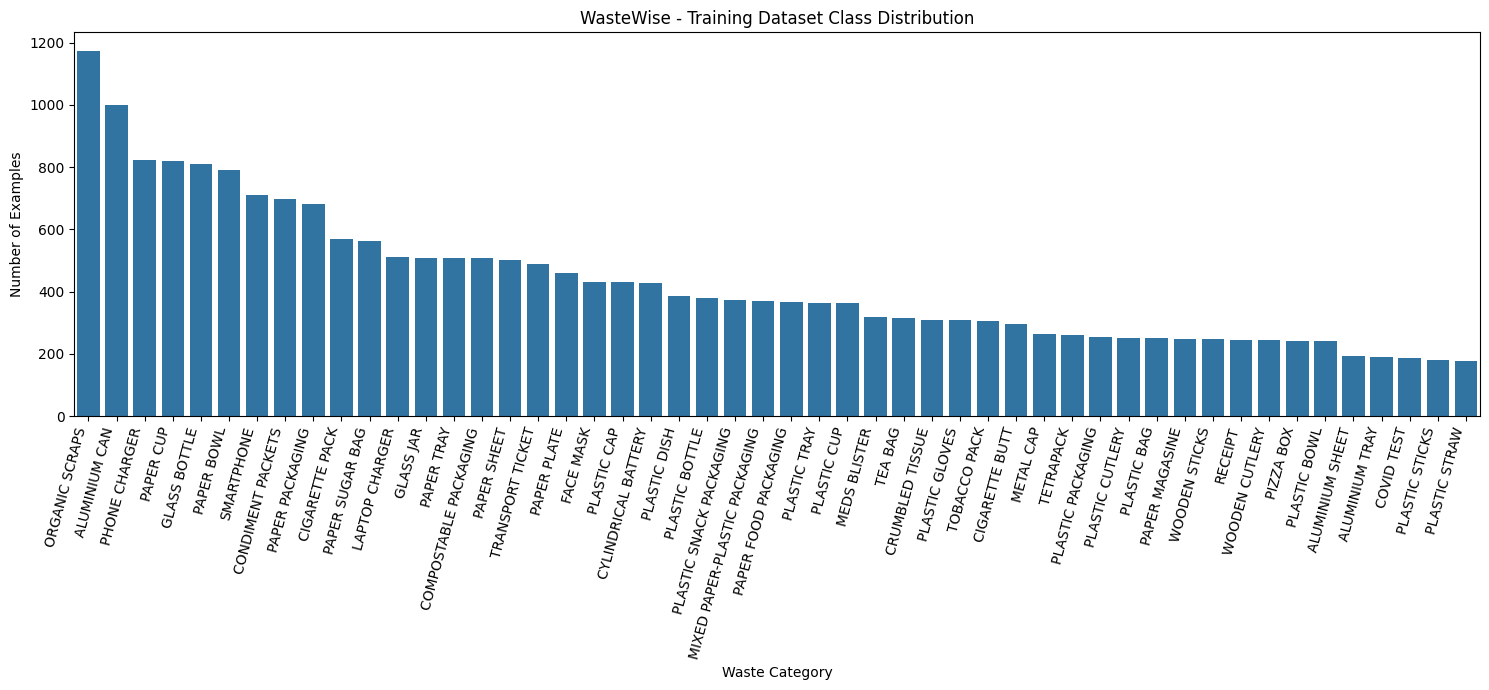

In [7]:
class_counts = train_df["Class"].value_counts()

print(class_counts)

plt.figure(figsize=(15, 7))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("WasteWise - Training Dataset Class Distribution")
plt.xlabel("Waste Category")
plt.ylabel("Number of Examples")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

In [8]:
# Check missing values in training data
print("Missing values in training dataset:\n")
print(train_df.isnull().sum())

print("\nMissing values in testing dataset:\n")
print(test_df.isnull().sum())

Missing values in training dataset:

Unnamed: 0     0
Phrase         0
Class          0
Class_index    0
dtype: int64

Missing values in testing dataset:

Unnamed: 0     0
Phrase         0
Class          0
Class_index    0
dtype: int64


In [9]:
# Count exact duplicate phrases in training data
train_duplicates = train_df["Phrase"].duplicated().sum()

# Count exact duplicate phrases in testing data
test_duplicates = test_df["Phrase"].duplicated().sum()

print("Duplicate phrases in training:", train_duplicates)
print("Duplicate phrases in testing:", test_duplicates)

# Check if identical phrases have conflicting labels
conflicting_labels = (
    train_df.groupby("Phrase")["Class"]
    .nunique()
)

conflicts = conflicting_labels[conflicting_labels > 1]

print("\nIdentical phrases with conflicting labels:",
      len(conflicts))

Duplicate phrases in training: 1142
Duplicate phrases in testing: 118

Identical phrases with conflicting labels: 384


In [10]:
# Find phrases that have more than one associated class
conflicting_phrases = (
    train_df.groupby("Phrase")["Class"]
    .nunique()
)

conflicting_phrases = conflicting_phrases[
    conflicting_phrases > 1
].index

# Display examples of conflicting records
conflict_examples = (
    train_df[
        train_df["Phrase"].isin(conflicting_phrases)
    ]
    .sort_values("Phrase")
)

display(conflict_examples.head(20))

,Unnamed: 0,Phrase,Class,Class_index
19209,2886,Can I recycle a biodegradable packaging ?,COMPOSTABLE PACKAGING,5.0
18541,14352,Can I recycle a biodegradable packaging ?,PAPER PACKAGING,21.0
9341,11388,Can I recycle a disposable bowl ?,PAPER BOWL,18.0
18505,19344,Can I recycle a disposable bowl ?,PLASTIC BOWL,30.0
12133,21840,Can I recycle a plastic containers ?,PLASTIC PACKAGING,36.0
7748,21060,Can I recycle a plastic containers ?,PLASTIC DISH,34.0
1034,19188,Can I recycle a plastic dish ?,PLASTIC BOWL,30.0
9973,24180,Can I recycle a plastic dish ?,PLASTIC TRAY,42.0
12508,14040,Can I recycle a recyclable packaging ?,PAPER PACKAGING,21.0
9138,3198,Can I recycle a recyclable packaging ?,COMPOSTABLE PACKAGING,5.0


In [11]:
# Find conflicting phrases in the testing set
test_conflicts = (
    test_df.groupby("Phrase")["Class"]
    .nunique()
)

test_conflicts = test_conflicts[test_conflicts > 1]

print("Conflicting phrase groups in test:",
      len(test_conflicts))

# Check exact phrase overlap between training and testing
train_phrases = set(
    train_df["Phrase"].str.lower().str.strip()
)

test_phrases = set(
    test_df["Phrase"].str.lower().str.strip()
)

overlap = train_phrases.intersection(test_phrases)

print("Exact phrase overlap between train and test:",
      len(overlap))

# Show a few overlapping examples
if overlap:
    overlap_examples = train_df[
        train_df["Phrase"].str.lower().str.strip().isin(overlap)
    ]

    display(overlap_examples.head(10))

Conflicting phrase groups in test: 28
Exact phrase overlap between train and test: 429


,Unnamed: 0,Phrase,Class,Class_index
1,20094,Should I recycle a disposable cup ?,PLASTIC CUP,32.0
14,19386,Open for my majestic disposable bowl,PLASTIC BOWL,30.0
67,3230,"I have my recyclable packaging, where should I...",COMPOSTABLE PACKAGING,5.0
140,9426,Where does my rest of xiaomi phone go ?,SMARTPHONE,16.0
167,18087,Where does my rest of pizza box go ?,PIZZA BOX,27.0
200,14084,Open for my majestic recyclable packaging,PAPER PACKAGING,21.0
223,11117,Open for my majestic bread,ORGANIC SCRAPS,17.0
327,10287,Where does my rest of grape go ?,ORGANIC SCRAPS,17.0
398,4282,Where does my rest of mayonnaise packets go ?,CONDIMENT PACKETS,6.0
413,26747,Where does my rest of pack of rolls go ?,TOBACCO PACK,49.0


In [12]:
# Normalize phrases to avoid differences in capitalization or whitespace
train_df["normalized_phrase"] = (
    train_df["Phrase"].str.lower().str.strip()
)

test_df["normalized_phrase"] = (
    test_df["Phrase"].str.lower().str.strip()
)

# Collect the set of labels assigned to each phrase in each split
train_labels = (
    train_df.groupby("normalized_phrase")["Class"]
    .agg(set)
)

test_labels = (
    test_df.groupby("normalized_phrase")["Class"]
    .agg(set)
)

# Find phrases that appear in both splits
shared_phrases = set(train_labels.index) & set(test_labels.index)

# Find shared phrases whose labels differ between splits
cross_split_conflicts = [
    phrase for phrase in shared_phrases
    if train_labels[phrase] != test_labels[phrase]
]

print("Shared unique phrases:", len(shared_phrases))
print("Shared phrases with different label sets:",
      len(cross_split_conflicts))

# Display a few examples
for phrase in cross_split_conflicts[:10]:
    print("\nPhrase:", phrase)
    print("Training labels:", train_labels[phrase])
    print("Testing labels:", test_labels[phrase])

Shared unique phrases: 429
Shared phrases with different label sets: 186

Phrase: hi trash, where should i discard this recyclable packaging ?
Training labels: {'COMPOSTABLE PACKAGING'}
Testing labels: {'PAPER PACKAGING'}

Phrase: excuse me, can you help me ? i have to throw a plastic dish
Training labels: {'PLASTIC DISH', 'PLASTIC TRAY'}
Testing labels: {'PLASTIC BOWL'}

Phrase: where do i have to throw a disposable bowl ?
Training labels: {'PLASTIC BOWL'}
Testing labels: {'PAPER BOWL'}

Phrase: where to throw this sustainable packaging ?
Training labels: {'COMPOSTABLE PACKAGING'}
Testing labels: {'PAPER PACKAGING'}

Phrase: where do i have to throw this disposable cup ?
Training labels: {'PLASTIC CUP'}
Testing labels: {'PAPER CUP'}

Phrase: is there anyway i could get rid of my compostable packaging ?
Training labels: {'PAPER PACKAGING'}
Testing labels: {'COMPOSTABLE PACKAGING'}

Phrase: where does my rest of sustainable packaging go ?
Training labels: {'PAPER PACKAGING', 'COMPOSTABL

In [13]:
# Count shared phrases with completely different label sets
disjoint_conflicts = [
    phrase for phrase in shared_phrases
    if train_labels[phrase].isdisjoint(test_labels[phrase])
]

# Count shared phrases with partially overlapping label sets
partial_conflicts = [
    phrase for phrase in shared_phrases
    if (
        train_labels[phrase] != test_labels[phrase]
        and not train_labels[phrase].isdisjoint(test_labels[phrase])
    )
]

# Count phrases with exactly matching label sets
matching_labels = [
    phrase for phrase in shared_phrases
    if train_labels[phrase] == test_labels[phrase]
]

print("Completely disjoint label conflicts:", len(disjoint_conflicts))
print("Partially overlapping label conflicts:", len(partial_conflicts))
print("Identical label sets:", len(matching_labels))

Completely disjoint label conflicts: 178
Partially overlapping label conflicts: 8
Identical label sets: 243


In [14]:
# Count how many training rows belong to repeated phrases
phrase_counts = train_df["normalized_phrase"].value_counts()

unique_phrase_count = train_df["normalized_phrase"].nunique()

repeated_phrase_count = (phrase_counts > 1).sum()

extra_duplicate_rows = len(train_df) - unique_phrase_count

print("Total training rows:", len(train_df))
print("Unique normalized phrases:", unique_phrase_count)
print("Phrases appearing more than once:", repeated_phrase_count)
print("Extra repeated rows:", extra_duplicate_rows)

# Distribution of how frequently phrases occur
print("\nFrequency distribution:")
print(phrase_counts.value_counts().sort_index().head(10))

Total training rows: 21528
Unique normalized phrases: 20386
Phrases appearing more than once: 822
Extra repeated rows: 1142

Frequency distribution:
count
1    19564
2      522
3      289
4        4
5        5
6        2
Name: count, dtype: int64


In [15]:
# Count distinct labels assigned to each normalized phrase
train_label_counts = (
    train_df.groupby("normalized_phrase")["Class"]
    .nunique()
)

# Repeated phrases with only one assigned label
consistent_repeated = train_label_counts[
    (train_df["normalized_phrase"].value_counts() > 1)
    & (train_label_counts == 1)
]

# Repeated phrases assigned multiple labels
conflicting_repeated = train_label_counts[
    (train_df["normalized_phrase"].value_counts() > 1)
    & (train_label_counts > 1)
]

print("Repeated phrases with consistent labels:",
      len(consistent_repeated))

print("Repeated phrases with conflicting labels:",
      len(conflicting_repeated))

Repeated phrases with consistent labels: 438
Repeated phrases with conflicting labels: 384


In [16]:
# Check whether each class maps to exactly one numeric index
class_to_index = (
    train_df.groupby("Class")["Class_index"].nunique()
)

# Check whether each numeric index maps to exactly one class
index_to_class = (
    train_df.groupby("Class_index")["Class"].nunique()
)

print(
    "Classes mapped to multiple indices:",
    (class_to_index > 1).sum()
)

print(
    "Indices mapped to multiple classes:",
    (index_to_class > 1).sum()
)

print(
    "Unique numeric indices:",
    train_df["Class_index"].nunique()
)

Classes mapped to multiple indices: 0
Indices mapped to multiple classes: 0
Unique numeric indices: 50


In [17]:
# Build class-to-index mappings for both splits
train_mapping = (
    train_df.groupby("Class")["Class_index"].first()
)

test_mapping = (
    test_df.groupby("Class")["Class_index"].first()
)

# Compare mappings for classes present in both splits
common_classes = set(train_mapping.index) & set(test_mapping.index)

mapping_mismatches = [
    cls for cls in common_classes
    if train_mapping[cls] != test_mapping[cls]
]

print("Classes present in both splits:", len(common_classes))
print("Class-index mapping mismatches:", len(mapping_mismatches))

if mapping_mismatches:
    print("\nExamples:")
    for cls in mapping_mismatches[:10]:
        print(
            cls,
            "| Train:", train_mapping[cls],
            "| Test:", test_mapping[cls]
        )

Classes present in both splits: 50
Class-index mapping mismatches: 0


In [18]:
# Calculate word counts for training phrases
train_df["word_count"] = (
    train_df["Phrase"]
    .str.split()
    .str.len()
)

print("Word count statistics:")
print(train_df["word_count"].describe())

print("\nShortest phrases:")
display(
    train_df.nsmallest(10, "word_count")[["Phrase", "Class", "word_count"]]
)

print("\nLongest phrases:")
display(
    train_df.nlargest(10, "word_count")[["Phrase", "Class", "word_count"]]
)

Word count statistics:
count    21528.000000
mean         9.025641
std          2.574841
min          4.000000
25%          7.000000
50%          9.000000
75%         10.000000
max         20.000000
Name: word_count, dtype: float64

Shortest phrases:


,Phrase,Class,word_count
663,I have a rice,ORGANIC SCRAPS,4
904,I have a press,PAPER MAGASINE,4
1357,I have my pasta,ORGANIC SCRAPS,4
1481,I have my apple,ORGANIC SCRAPS,4
1577,I have a invoice,RECEIPT,4
1762,I have this rice,ORGANIC SCRAPS,4
2333,I have my strawberries,ORGANIC SCRAPS,4
2738,I have this diaries,PAPER SHEET,4
3490,I have my diaries,PAPER SHEET,4
4386,I have my cigarette,CIGARETTE BUTT,4



Longest phrases:


,Phrase,Class,word_count
1387,"Excuse me, can you help me ? I don't know wher...",MIXED PAPER-PLASTIC PACKAGING,20
2039,"Excuse me, can you help me ? I don't know wher...",MIXED PAPER-PLASTIC PACKAGING,20
8520,"Excuse me, can you help me ? I don't know wher...",MIXED PAPER-PLASTIC PACKAGING,19
14840,"Excuse me, can you help me ? I don't know wher...",MIXED PAPER-PLASTIC PACKAGING,19
20773,"Excuse me, can you help me ? I don't know wher...",MIXED PAPER-PLASTIC PACKAGING,19
1837,"Excuse me, can you help me ? I don't know wher...",GLASS BOTTLE,18
6584,"Excuse me, can you help me ? I don't know wher...",TOBACCO PACK,18
6621,"Excuse me, can you help me ? I don't know wher...",TOBACCO PACK,18
13671,"Excuse me, can you help me ? I don't know wher...",TOBACCO PACK,18
13829,"Excuse me, can you help me ? I don't know wher...",GLASS BOTTLE,18


In [19]:
# Extract the first three words from each phrase
train_df["opening_pattern"] = (
    train_df["Phrase"]
    .str.lower()
    .str.split()
    .str[:3]
    .str.join(" ")
)

# Find the most frequent opening patterns
top_patterns = train_df["opening_pattern"].value_counts().head(15)

print("Top 15 sentence-opening patterns:")
display(top_patterns.to_frame(name="Frequency"))

print(
    "\nUnique three-word opening patterns:",
    train_df["opening_pattern"].nunique()
)

Top 15 sentence-opening patterns:


,Frequency
opening_pattern,
where do i,1979
"excuse me, can",1300
where can i,1293
in which bin,1276
i have my,1116
i have this,1095
i have a,1080
where does my,1063
"hey, in which",710



Unique three-word opening patterns: 384


In [20]:
# Extract the first three words from test phrases
test_df["opening_pattern"] = (
    test_df["Phrase"]
    .str.lower()
    .str.split()
    .str[:3]
    .str.join(" ")
)

# Compare unique opening patterns across splits
train_openings = set(train_df["opening_pattern"])
test_openings = set(test_df["opening_pattern"])

shared_openings = train_openings & test_openings
unseen_test_openings = test_openings - train_openings

print("Unique training opening patterns:", len(train_openings))
print("Unique testing opening patterns:", len(test_openings))
print("Opening patterns shared across splits:", len(shared_openings))
print("Opening patterns exclusive to test:", len(unseen_test_openings))

print("\nExamples of test-only opening patterns:")
print(list(unseen_test_openings)[:15])

Unique training opening patterns: 384
Unique testing opening patterns: 166
Opening patterns shared across splits: 90
Opening patterns exclusive to test: 76

Examples of test-only opening patterns:
['is this capsule', 'is a crumpled', 'is my strawberries', 'is this gauloises', 'is a books', 'is my covid', 'is my package', 'is my packet', 'is this lenovo', 'is this fiber-based', 'is this hp', 'is a alkaline', 'is this pill', 'is a philip', 'is a l&m']


In [21]:
# Identify whether each test phrase starts with a training-seen pattern
train_openings = set(train_df["opening_pattern"])

test_df["opening_seen_in_train"] = (
    test_df["opening_pattern"].isin(train_openings)
)

# Count test rows by opening-pattern familiarity
opening_counts = (
    test_df["opening_seen_in_train"]
    .value_counts()
)

seen_rows = opening_counts.get(True, 0)
unseen_rows = opening_counts.get(False, 0)

print("Test rows with familiar openings:", seen_rows)
print("Test rows with unseen openings:", unseen_rows)

print(
    "Percentage with familiar openings:",
    round(seen_rows / len(test_df) * 100, 2), "%"
)

print(
    "Percentage with unseen openings:",
    round(unseen_rows / len(test_df) * 100, 2), "%"
)


Test rows with familiar openings: 5302
Test rows with unseen openings: 80
Percentage with familiar openings: 98.51 %
Percentage with unseen openings: 1.49 %


In [22]:
# Inspect phrases containing potentially ambiguous item descriptions
keywords = [
    "disposable bowl",
    "biodegradable packaging",
    "recyclable packaging",
    "plastic dish",
    "sustainable packaging"
]

for keyword in keywords:
    matching_rows = train_df[
        train_df["Phrase"].str.contains(
            keyword, case=False, regex=False
        )
    ]

    print(f"\nKeyword: {keyword}")
    print("Rows:", len(matching_rows))
    print("Assigned labels:")
    print(matching_rows["Class"].value_counts())


Keyword: disposable bowl
Rows: 130
Assigned labels:
Class
PLASTIC BOWL    65
PAPER BOWL      65
Name: count, dtype: int64

Keyword: biodegradable packaging
Rows: 130
Assigned labels:
Class
COMPOSTABLE PACKAGING    68
PAPER PACKAGING          62
Name: count, dtype: int64

Keyword: recyclable packaging
Rows: 123
Assigned labels:
Class
COMPOSTABLE PACKAGING    64
PAPER PACKAGING          59
Name: count, dtype: int64

Keyword: plastic dish
Rows: 183
Assigned labels:
Class
PLASTIC TRAY    64
PLASTIC DISH    61
PLASTIC BOWL    58
Name: count, dtype: int64

Keyword: sustainable packaging
Rows: 127
Assigned labels:
Class
COMPOSTABLE PACKAGING    66
PAPER PACKAGING          61
Name: count, dtype: int64


In [23]:
# Identify phrases assigned more than one class
phrase_label_counts = (
    train_df.groupby("normalized_phrase")["Class"].nunique()
)

conflicting_phrases = phrase_label_counts[
    phrase_label_counts > 1
].index

# Retrieve every row belonging to those phrases
conflicting_rows = train_df[
    train_df["normalized_phrase"].isin(conflicting_phrases)
]

print("Unique conflicting phrases:", len(conflicting_phrases))
print("Training rows affected:", len(conflicting_rows))

print(
    "Percentage of training rows affected:",
    round(len(conflicting_rows) / len(train_df) * 100, 2),
    "%"
)

Unique conflicting phrases: 384
Training rows affected: 821
Percentage of training rows affected: 3.81 %


In [24]:
# Count conflicting rows by assigned class
conflict_class_distribution = (
    conflicting_rows["Class"]
    .value_counts()
)

print("Conflicting rows by class:")
display(
    conflict_class_distribution.to_frame(
        name="Conflicting rows"
    )
)

Conflicting rows by class:


,Conflicting rows
Class,
COMPOSTABLE PACKAGING,207
PAPER PACKAGING,205
PLASTIC BOWL,100
PLASTIC DISH,92
PLASTIC TRAY,57
PAPER BOWL,45
PLASTIC PACKAGING,43
PAPER CUP,36
PLASTIC CUP,36


In [25]:
# Identify test phrases with multiple assigned labels
test_label_counts = (
    test_df.groupby("normalized_phrase")["Class"].nunique()
)

test_conflicting_phrases = test_label_counts[
    test_label_counts > 1
].index

# Retrieve all test rows belonging to conflicting phrases
test_conflicting_rows = test_df[
    test_df["normalized_phrase"].isin(test_conflicting_phrases)
]

print("Unique conflicting test phrases:",
      len(test_conflicting_phrases))

print("Test rows affected:",
      len(test_conflicting_rows))

print(
    "Percentage of test rows affected:",
    round(len(test_conflicting_rows) / len(test_df) * 100, 2),
    "%"
)

Unique conflicting test phrases: 28
Test rows affected: 56
Percentage of test rows affected: 1.04 %


In [26]:
test_class_counts = (
    test_df["Class"]
    .value_counts()
    .sort_values()
)

print("Test-set class distribution:")
display(test_class_counts.to_frame(name="Test examples"))

print("\nSmallest test class:", test_class_counts.min())
print("Largest test class:", test_class_counts.max())
print("Classes with fewer than 30 examples:",
      (test_class_counts < 30).sum())

Test-set class distribution:


,Test examples
Class,
ALUMINIUM SHEET,41
ALUMINIUM TRAY,45
METAL CAP,48
COVID TEST,48
TETRAPACK,52
PLASTIC STICKS,55
PLASTIC PACKAGING,57
PLASTIC STRAW,57
PLASTIC BAG,61



Smallest test class: 41
Largest test class: 308
Classes with fewer than 30 examples: 0


In [27]:
# Total training examples per class
total_per_class = train_df["Class"].value_counts()

# Conflicting training examples per class
conflicts_per_class = conflicting_rows["Class"].value_counts()

# Calculate percentage affected
conflict_analysis = pd.DataFrame({
    "Total examples": total_per_class,
    "Conflicting examples": conflicts_per_class
}).fillna(0)

conflict_analysis["Conflicting examples"] = (
    conflict_analysis["Conflicting examples"].astype(int)
)

conflict_analysis["Conflict rate (%)"] = (
    conflict_analysis["Conflicting examples"]
    / conflict_analysis["Total examples"] * 100
).round(2)

print("Top 10 classes by annotation conflict rate:")

display(
    conflict_analysis
    .sort_values("Conflict rate (%)", ascending=False)
    .head(10)
)

Top 10 classes by annotation conflict rate:


,Total examples,Conflicting examples,Conflict rate (%)
Class,,,
PLASTIC BOWL,240,100,41.67
COMPOSTABLE PACKAGING,508,207,40.75
PAPER PACKAGING,682,205,30.06
PLASTIC DISH,385,92,23.90
PLASTIC PACKAGING,255,43,16.86
PLASTIC TRAY,363,57,15.70
PLASTIC CUP,362,36,9.94
PAPER BOWL,791,45,5.69
PAPER CUP,820,36,4.39


In [28]:
from itertools import combinations
from collections import Counter

# Normalize phrases so minor capitalization and spacing differences
# do not create separate phrase groups.
train_df["Phrase_norm"] = (
    train_df["Phrase"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Get the distinct labels assigned to each normalized phrase.
phrase_labels = (
    train_df.groupby("Phrase_norm")["Class"]
    .apply(lambda labels: sorted(set(labels)))
)

# Count how many unique phrase groups contain each conflicting label pair.
pair_counts = Counter()

for labels in phrase_labels:
    if len(labels) > 1:
        for pair in combinations(labels, 2):
            pair_counts[pair] += 1

conflict_pairs_df = pd.DataFrame(
    [
        {
            "Class pair": f"{pair[0]} ↔ {pair[1]}",
            "Conflicting phrase groups": count
        }
        for pair, count in pair_counts.most_common()
    ]
)

print("Total conflicting class pairs:", len(conflict_pairs_df))
display(conflict_pairs_df.head(15))

Total conflicting class pairs: 7


,Class pair,Conflicting phrase groups
0,COMPOSTABLE PACKAGING ↔ PAPER PACKAGING,196
1,PAPER BOWL ↔ PLASTIC BOWL,44
2,PLASTIC DISH ↔ PLASTIC PACKAGING,41
3,PLASTIC BOWL ↔ PLASTIC TRAY,41
4,PLASTIC DISH ↔ PLASTIC TRAY,36
5,PLASTIC BOWL ↔ PLASTIC DISH,35
6,PAPER CUP ↔ PLASTIC CUP,35


In [29]:
# Inspect representative phrases for each conflicting class pair

for pair, count in pair_counts.most_common():

    matching_phrases = phrase_labels[
        phrase_labels.apply(lambda labels: set(labels) == set(pair))
    ]

    print("\n" + "=" * 85)
    print(f"{pair[0]} ↔ {pair[1]} | {len(matching_phrases)} phrase groups")
    print("=" * 85)

    for phrase in matching_phrases.index[:5]:
        print("-", phrase)


COMPOSTABLE PACKAGING ↔ PAPER PACKAGING | 196 phrase groups
- can i recycle a biodegradable packaging ?
- can i recycle a recyclable packaging ?
- can i recycle a sustainable packaging ?
- can i recycle my biodegradable packaging ?
- can i recycle my eco-friendly packaging ?

PAPER BOWL ↔ PLASTIC BOWL | 44 phrase groups
- can i recycle a disposable bowl ?
- could i throw a disposable bowl in this trash ?
- could i throw my disposable bowl in this trash ?
- excuse me, can you help me ? i have to throw my disposable bowl
- excuse me, can you help me ? i have to throw this disposable bowl

PLASTIC DISH ↔ PLASTIC PACKAGING | 41 phrase groups
- can i recycle a plastic containers ?
- can i recycle this plastic containers ?
- could i throw a plastic containers in this trash ?
- could i throw my plastic containers in this trash ?
- could i throw this plastic containers in this trash ?

PLASTIC BOWL ↔ PLASTIC TRAY | 19 phrase groups
- can i recycle a plastic dish ?
- hi trash, where should i d

In [30]:
import pandas as pd

print("DATAFRAMES CURRENTLY LOADED\n")

dataframes = {
    name: obj
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

if not dataframes:
    print("No pandas DataFrames found. The runtime may need the dataset reloaded.")
else:
    for name, data in dataframes.items():
        print(f"\nVariable: {name}")
        print(f"Shape: {data.shape}")
        print(f"Columns: {data.columns.tolist()}")
        print("-" * 60)

# Check our expected training/test variables
for name in ["train_df", "test_df"]:
    if name in globals():
        print(f"\n{name} preview:")
        display(globals()[name].head(3))

DATAFRAMES CURRENTLY LOADED


Variable: train_df
Shape: (21528, 8)
Columns: ['Unnamed: 0', 'Phrase', 'Class', 'Class_index', 'normalized_phrase', 'word_count', 'opening_pattern', 'Phrase_norm']
------------------------------------------------------------

Variable: test_df
Shape: (5382, 7)
Columns: ['Unnamed: 0', 'Phrase', 'Class', 'Class_index', 'normalized_phrase', 'opening_pattern', 'opening_seen_in_train']
------------------------------------------------------------

Variable: conflict_examples
Shape: (821, 4)
Columns: ['Unnamed: 0', 'Phrase', 'Class', 'Class_index']
------------------------------------------------------------

Variable: overlap_examples
Shape: (649, 4)
Columns: ['Unnamed: 0', 'Phrase', 'Class', 'Class_index']
------------------------------------------------------------

Variable: matching_rows
Shape: (127, 7)
Columns: ['Unnamed: 0', 'Phrase', 'Class', 'Class_index', 'normalized_phrase', 'word_count', 'opening_pattern']
---------------------------------------------

,Unnamed: 0,Phrase,Class,Class_index,normalized_phrase,word_count,opening_pattern,Phrase_norm
0,17110,"I have this apple phone charger to throw, wher...",PHONE CHARGER,26.0,"i have this apple phone charger to throw, wher...",14,i have this,"i have this apple phone charger to throw, wher..."
1,20094,Should I recycle a disposable cup ?,PLASTIC CUP,32.0,should i recycle a disposable cup ?,7,should i recycle,should i recycle a disposable cup ?
2,5638,"I have this surgical masks, where should I thr...",FACE MASK,10.0,"i have this surgical masks, where should i thr...",11,i have this,"i have this surgical masks, where should i thr..."



test_df preview:


,Unnamed: 0,Phrase,Class,Class_index,normalized_phrase,opening_pattern,opening_seen_in_train
0,1806,"Hey, in which trash does a cigarette end goes ...",CIGARETTE BUTT,3.0,"hey, in which trash does a cigarette end goes ...","hey, in which",True
1,3871,Where can I put this spice packets ?,CONDIMENT PACKETS,6.0,where can i put this spice packets ?,where can i,True
2,3791,Open for my majestic flavor packets,CONDIMENT PACKETS,6.0,open for my majestic flavor packets,open for my,True


In [31]:
# Count how many distinct labels are assigned to each normalized phrase
phrase_label_counts = (
    train_df.groupby("normalized_phrase")["Class"]
    .nunique()
    .reset_index(name="number_of_classes")
)

# Find phrases assigned to 3 or more different classes
multi_class_phrases = phrase_label_counts[
    phrase_label_counts["number_of_classes"] >= 3
].sort_values("number_of_classes", ascending=False)

print("Total normalized phrases assigned to 3+ classes:",
      len(multi_class_phrases))

print("\nDistribution:")
print(multi_class_phrases["number_of_classes"].value_counts().sort_index())

# Display the actual records for inspection
if not multi_class_phrases.empty:
    display(
        train_df[
            train_df["normalized_phrase"].isin(
                multi_class_phrases["normalized_phrase"]
            )
        ][["Phrase", "normalized_phrase", "Class"]]
        .sort_values(["normalized_phrase", "Class"])
        .head(40)
    )

Total normalized phrases assigned to 3+ classes: 22

Distribution:
number_of_classes
3    22
Name: count, dtype: int64


,Phrase,normalized_phrase,Class
17699,Can I recycle this plastic dish ?,can i recycle this plastic dish ?,PLASTIC BOWL
16575,Can I recycle this plastic dish ?,can i recycle this plastic dish ?,PLASTIC DISH
19406,Can I recycle this plastic dish ?,can i recycle this plastic dish ?,PLASTIC TRAY
9844,"Excuse me, can you help me ? I have to throw m...","excuse me, can you help me ? i have to throw m...",PLASTIC BOWL
13572,"Excuse me, can you help me ? I have to throw m...","excuse me, can you help me ? i have to throw m...",PLASTIC DISH
13174,"Excuse me, can you help me ? I have to throw m...","excuse me, can you help me ? i have to throw m...",PLASTIC TRAY
8651,"Excuse me, can you help me ? I have to throw t...","excuse me, can you help me ? i have to throw t...",PLASTIC BOWL
14322,"Excuse me, can you help me ? I have to throw t...","excuse me, can you help me ? i have to throw t...",PLASTIC DISH
8805,"Excuse me, can you help me ? I have to throw t...","excuse me, can you help me ? i have to throw t...",PLASTIC TRAY
15965,"Hey, in which trash does a plastic dish goes ?...","hey, in which trash does a plastic dish goes ?...",PLASTIC BOWL


In [32]:
# Get all rows belonging to the 22 multi-class phrase groups
multi_class_rows = train_df[
    train_df["normalized_phrase"].isin(
        multi_class_phrases["normalized_phrase"]
    )
].copy()

# Summarise each phrase group
multi_class_summary = (
    multi_class_rows.groupby("normalized_phrase")
    .agg(
        total_rows=("Class", "size"),
        number_of_classes=("Class", "nunique"),
        labels=("Class", lambda x: sorted(x.unique().tolist())),
        original_phrases=("Phrase", lambda x: sorted(x.unique().tolist()))
    )
    .reset_index()
)

print("Total affected training rows:", len(multi_class_rows))
print("Total conflicting phrase groups:", len(multi_class_summary))
print("Total distinct original sentences:",
      multi_class_rows["Phrase"].nunique())

display(multi_class_summary)

Total affected training rows: 66
Total conflicting phrase groups: 22
Total distinct original sentences: 22


,normalized_phrase,total_rows,number_of_classes,labels,original_phrases
0,can i recycle this plastic dish ?,3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]",[Can I recycle this plastic dish ?]
1,"excuse me, can you help me ? i have to throw m...",3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]","[Excuse me, can you help me ? I have to throw ..."
2,"excuse me, can you help me ? i have to throw t...",3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]","[Excuse me, can you help me ? I have to throw ..."
3,"hey, in which trash does a plastic dish goes ?...",3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]","[Hey, in which trash does a plastic dish goes ..."
4,"hey, in which trash does my plastic dish goes ...",3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]","[Hey, in which trash does my plastic dish goes..."
5,"hi trash, where should i discard a plastic dish ?",3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]","[Hi trash, where should I discard a plastic di..."
6,i have my plastic dish to throw,3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]",[I have my plastic dish to throw]
7,"i have my plastic dish, where should i throw it ?",3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]","[I have my plastic dish, where should I throw ..."
8,i have this plastic dish to throw,3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]",[I have this plastic dish to throw]
9,i wonder where i should throw my plastic dish ?,3,3,"[PLASTIC BOWL, PLASTIC DISH, PLASTIC TRAY]",[I wonder where I should throw my plastic dish ?]


In [33]:
# Count distinct labels assigned to each normalized phrase
phrase_label_counts = (
    train_df.groupby("normalized_phrase")["Class"]
    .nunique()
)

# Identify exactly two-class conflicts
two_class_phrases = phrase_label_counts[
    phrase_label_counts == 2
].index

two_class_rows = train_df[
    train_df["normalized_phrase"].isin(two_class_phrases)
].copy()

# Summarise the label combinations
two_class_summary = (
    two_class_rows.groupby("normalized_phrase")
    .agg(
        total_rows=("Class", "size"),
        labels=("Class", lambda x: sorted(x.unique().tolist()))
    )
    .reset_index()
)

# Count how many phrase groups belong to each label pair
two_class_summary["class_pair"] = two_class_summary["labels"].apply(
    lambda x: " vs ".join(x)
)

pair_distribution = (
    two_class_summary["class_pair"]
    .value_counts()
    .rename_axis("Class pair")
    .reset_index(name="Conflicting phrase groups")
)

print("Two-class conflicting phrase groups:",
      len(two_class_summary))

print("Affected training rows:", len(two_class_rows))

print("\nDistribution by label pair:")
display(pair_distribution)

Two-class conflicting phrase groups: 362
Affected training rows: 755

Distribution by label pair:


,Class pair,Conflicting phrase groups
0,COMPOSTABLE PACKAGING vs PAPER PACKAGING,196
1,PAPER BOWL vs PLASTIC BOWL,44
2,PLASTIC DISH vs PLASTIC PACKAGING,41
3,PAPER CUP vs PLASTIC CUP,35
4,PLASTIC BOWL vs PLASTIC TRAY,19
5,PLASTIC DISH vs PLASTIC TRAY,14
6,PLASTIC BOWL vs PLASTIC DISH,13


In [34]:
# Build label sets for each normalized phrase in both splits
train_labels = (
    train_df.groupby("normalized_phrase")["Class"]
    .agg(lambda x: set(x))
)

test_labels = (
    test_df.groupby("normalized_phrase")["Class"]
    .agg(lambda x: set(x))
)

# Identify phrases appearing in both splits
shared_phrases = set(train_labels.index) & set(test_labels.index)

# Compare label sets across splits
overlap_comparison = pd.DataFrame({
    "normalized_phrase": list(shared_phrases)
})

overlap_comparison["train_labels"] = overlap_comparison[
    "normalized_phrase"
].map(train_labels)

overlap_comparison["test_labels"] = overlap_comparison[
    "normalized_phrase"
].map(test_labels)

overlap_comparison["same_label_sets"] = (
    overlap_comparison["train_labels"] ==
    overlap_comparison["test_labels"]
)

print("Shared normalized phrases:", len(overlap_comparison))
print("\nLabel-set agreement:")
print(overlap_comparison["same_label_sets"].value_counts())

print("\nExamples with different label sets:")
display(
    overlap_comparison[
        ~overlap_comparison["same_label_sets"]
    ].head(20)
)

Shared normalized phrases: 429

Label-set agreement:
same_label_sets
True     243
False    186
Name: count, dtype: int64

Examples with different label sets:


,normalized_phrase,train_labels,test_labels,same_label_sets
2,"hi trash, where should i discard this recyclab...",{COMPOSTABLE PACKAGING},{PAPER PACKAGING},False
3,"excuse me, can you help me ? i have to throw a...","{PLASTIC DISH, PLASTIC TRAY}",{PLASTIC BOWL},False
5,where do i have to throw a disposable bowl ?,{PLASTIC BOWL},{PAPER BOWL},False
6,where to throw this sustainable packaging ?,{COMPOSTABLE PACKAGING},{PAPER PACKAGING},False
7,where do i have to throw this disposable cup ?,{PLASTIC CUP},{PAPER CUP},False
11,is there anyway i could get rid of my composta...,{PAPER PACKAGING},{COMPOSTABLE PACKAGING},False
12,where does my rest of sustainable packaging go ?,"{PAPER PACKAGING, COMPOSTABLE PACKAGING}",{PAPER PACKAGING},False
13,where can i throw my plastic containers ?,{PLASTIC PACKAGING},{PLASTIC DISH},False
15,"i have this recyclable packaging, where do i t...",{COMPOSTABLE PACKAGING},{PAPER PACKAGING},False
21,where do i throw my biodegradable packaging,{COMPOSTABLE PACKAGING},{PAPER PACKAGING},False


In [35]:
# Identify rows belonging to shared normalized phrases
train_overlap = train_df[
    train_df["normalized_phrase"].isin(shared_phrases)
].copy()

test_overlap = test_df[
    test_df["normalized_phrase"].isin(shared_phrases)
].copy()

# Categorise shared phrase groups
def classify_overlap(row):
    train_set = row["train_labels"]
    test_set = row["test_labels"]

    if train_set != test_set:
        return "Different label sets"
    elif len(train_set) > 1:
        return "Same multiple labels"
    else:
        return "Same single label"

overlap_comparison["overlap_type"] = overlap_comparison.apply(
    classify_overlap, axis=1
)

print("OVERLAP SUMMARY")
print("-" * 45)
print("Shared phrase groups:", len(shared_phrases))
print("Affected training rows:", len(train_overlap))
print("Affected testing rows:", len(test_overlap))

print("\nPhrase group categories:")
print(overlap_comparison["overlap_type"].value_counts())

print("\nTraining rows as percentage of training set:",
      round(len(train_overlap) / len(train_df) * 100, 2), "%")

print("Testing rows as percentage of testing set:",
      round(len(test_overlap) / len(test_df) * 100, 2), "%")

OVERLAP SUMMARY
---------------------------------------------
Shared phrase groups: 429
Affected training rows: 649
Affected testing rows: 510

Phrase group categories:
overlap_type
Same single label       242
Different label sets    186
Same multiple labels      1
Name: count, dtype: int64

Training rows as percentage of training set: 3.01 %
Testing rows as percentage of testing set: 9.48 %


In [36]:
# Group training records by normalized phrase
phrase_group_stats = (
    train_df.groupby("normalized_phrase")
    .agg(
        total_rows=("Class", "size"),
        distinct_labels=("Class", "nunique"),
        labels=("Class", lambda x: sorted(x.unique().tolist()))
    )
    .reset_index()
)

# Groups repeated but having only one label
consistent_duplicate_groups = phrase_group_stats[
    (phrase_group_stats["total_rows"] > 1) &
    (phrase_group_stats["distinct_labels"] == 1)
].copy()

# Groups appearing exactly once
unique_phrase_groups = phrase_group_stats[
    phrase_group_stats["total_rows"] == 1
]

print("TOTAL TRAINING PHRASE GROUPS:", len(phrase_group_stats))

print("\nUnique phrase groups:", len(unique_phrase_groups))

print("\nConsistent duplicate groups:",
      len(consistent_duplicate_groups))

print("\nRows belonging to consistent duplicate groups:",
      consistent_duplicate_groups["total_rows"].sum())

print("\nExtra duplicate rows that could be removed:",
      (
          consistent_duplicate_groups["total_rows"] - 1
      ).sum())

print("\nMost repeated consistent phrases:")
display(
    consistent_duplicate_groups
    .sort_values("total_rows", ascending=False)
    .head(15)
)

TOTAL TRAINING PHRASE GROUPS: 20386

Unique phrase groups: 19564

Consistent duplicate groups: 438

Rows belonging to consistent duplicate groups: 1143

Extra duplicate rows that could be removed: 705

Most repeated consistent phrases:


,normalized_phrase,total_rows,distinct_labels,labels
12809,open for my majestic aluminium foil,3,1,[ALUMINIUM SHEET]
12810,open for my majestic aluminium plate,3,1,[ALUMINIUM SHEET]
12803,open for my majestic aa battery,3,1,[CYLINDRICAL BATTERY]
12811,open for my majestic aluminium sheet,3,1,[ALUMINIUM SHEET]
18565,where does my rest of tramway ticket go ?,3,1,[TRANSPORT TICKET]
18566,where does my rest of transport ticket go ?,3,1,[TRANSPORT TICKET]
18568,where does my rest of vivo phone charger go ?,3,1,[PHONE CHARGER]
18569,where does my rest of vogue pack go ?,3,1,[CIGARETTE PACK]
18570,where does my rest of water bottle cap go ?,3,1,[PLASTIC CAP]
18571,where does my rest of water bottle go ?,3,1,[PLASTIC BOTTLE]


In [37]:
# Group test records by normalized phrase
test_group_stats = (
    test_df.groupby("normalized_phrase")
    .agg(
        total_rows=("Class", "size"),
        distinct_labels=("Class", "nunique"),
        labels=("Class", lambda x: sorted(x.unique().tolist()))
    )
    .reset_index()
)

# Separate the three categories
test_unique_groups = test_group_stats[
    test_group_stats["total_rows"] == 1
]

test_consistent_duplicates = test_group_stats[
    (test_group_stats["total_rows"] > 1) &
    (test_group_stats["distinct_labels"] == 1)
]

test_conflict_groups = test_group_stats[
    test_group_stats["distinct_labels"] > 1
]

print("TEST SET INTERNAL AUDIT")
print("-" * 45)

print("Total phrase groups:", len(test_group_stats))

print("\nUnique phrase groups:", len(test_unique_groups))

print("Consistent duplicate groups:",
      len(test_consistent_duplicates))

print("Conflicting phrase groups:",
      len(test_conflict_groups))

print("\nRows in consistent duplicate groups:",
      test_consistent_duplicates["total_rows"].sum())

print("Rows in conflicting groups:",
      test_conflict_groups["total_rows"].sum())

print("\nConflicting test examples:")
display(
    test_df[
        test_df["normalized_phrase"].isin(
            test_conflict_groups["normalized_phrase"]
        )
    ][["Phrase", "normalized_phrase", "Class"]]
    .sort_values("normalized_phrase")
    .head(20)
)

TEST SET INTERNAL AUDIT
---------------------------------------------
Total phrase groups: 5264

Unique phrase groups: 5154
Consistent duplicate groups: 82
Conflicting phrase groups: 28

Rows in consistent duplicate groups: 172
Rows in conflicting groups: 56

Conflicting test examples:


,Phrase,normalized_phrase,Class
4748,Could I throw a eco-friendly packaging in this...,could i throw a eco-friendly packaging in this...,COMPOSTABLE PACKAGING
4299,Could I throw a eco-friendly packaging in this...,could i throw a eco-friendly packaging in this...,PAPER PACKAGING
2250,Could I throw my biodegradable packaging in th...,could i throw my biodegradable packaging in th...,PAPER PACKAGING
4127,Could I throw my biodegradable packaging in th...,could i throw my biodegradable packaging in th...,COMPOSTABLE PACKAGING
1990,Could I throw my plastic dish in this trash ?,could i throw my plastic dish in this trash ?,PLASTIC TRAY
1112,Could I throw my plastic dish in this trash ?,could i throw my plastic dish in this trash ?,PLASTIC DISH
4388,"Excuse me, can you help me ? I don't know wher...","excuse me, can you help me ? i don't know wher...",PAPER PACKAGING
3534,"Excuse me, can you help me ? I don't know wher...","excuse me, can you help me ? i don't know wher...",COMPOSTABLE PACKAGING
348,"Excuse me, can you help me ? I don't know wher...","excuse me, can you help me ? i don't know wher...",PAPER PACKAGING
460,"Excuse me, can you help me ? I don't know wher...","excuse me, can you help me ? i don't know wher...",COMPOSTABLE PACKAGING


In [38]:
# Compare class frequencies in training and testing datasets

train_distribution = train_df["Class"].value_counts()
test_distribution = test_df["Class"].value_counts()

class_distribution = pd.DataFrame({
    "Train_count": train_distribution,
    "Test_count": test_distribution
}).fillna(0).astype(int)

class_distribution["Total_count"] = (
    class_distribution["Train_count"] +
    class_distribution["Test_count"]
)

class_distribution["Train_percentage"] = (
    class_distribution["Train_count"] / len(train_df) * 100
).round(2)

class_distribution["Test_percentage"] = (
    class_distribution["Test_count"] / len(test_df) * 100
).round(2)

class_distribution = class_distribution.sort_values("Total_count")

print("Number of classes in training:", train_df["Class"].nunique())
print("Number of classes in testing:", test_df["Class"].nunique())

print("\nClasses missing from training:",
      sorted(set(test_df["Class"]) - set(train_df["Class"])))

print("\nClasses missing from testing:",
      sorted(set(train_df["Class"]) - set(test_df["Class"])))

print("\nSmallest 15 classes by total dataset frequency:")
display(class_distribution.head(15))

print("\nClass distribution statistics:")
display(class_distribution[["Train_count", "Test_count", "Total_count"]].describe())

Number of classes in training: 50
Number of classes in testing: 50

Classes missing from training: []

Classes missing from testing: []

Smallest 15 classes by total dataset frequency:


,Train_count,Test_count,Total_count,Train_percentage,Test_percentage
Class,,,,,
ALUMINIUM SHEET,193,41,234,0.90,0.76
ALUMINIUM TRAY,189,45,234,0.88,0.84
COVID TEST,186,48,234,0.86,0.89
PLASTIC STICKS,179,55,234,0.83,1.02
PLASTIC STRAW,177,57,234,0.82,1.06
PLASTIC BOWL,240,72,312,1.11,1.34
PLASTIC BAG,251,61,312,1.17,1.13
METAL CAP,264,48,312,1.23,0.89
WOODEN CUTLERY,243,69,312,1.13,1.28



Class distribution statistics:


,Train_count,Test_count,Total_count
count,50.000000,50.00000,50.000000
mean,430.560000,107.64000,538.200000
std,226.483334,56.49445,282.004559
min,177.000000,41.00000,234.000000
25%,252.000000,67.50000,312.000000
50%,368.000000,95.00000,468.000000
75%,508.000000,121.00000,624.000000
max,1174.000000,308.00000,1482.000000


In [39]:
# Analyse the most frequent phrase-opening patterns

train_openings = train_df["opening_pattern"].value_counts()

test_openings = test_df["opening_pattern"].value_counts()

opening_comparison = pd.DataFrame({
    "Train_count": train_openings,
    "Test_count": test_openings
}).fillna(0).astype(int)

opening_comparison["Total_count"] = (
    opening_comparison["Train_count"] +
    opening_comparison["Test_count"]
)

print("Unique opening patterns in training:",
      train_df["opening_pattern"].nunique())

print("Unique opening patterns in testing:",
      test_df["opening_pattern"].nunique())

print("\nTop 20 training opening patterns:")
display(opening_comparison.sort_values(
    "Train_count", ascending=False
).head(20))

print("\nTraining opening patterns also seen in testing:")
print(
    test_df["opening_seen_in_train"].value_counts(normalize=True)
    .mul(100).round(2)
)

Unique opening patterns in training: 384
Unique opening patterns in testing: 166

Top 20 training opening patterns:


,Train_count,Test_count,Total_count
opening_pattern,,,
where do i,1979,505,2484
"excuse me, can",1300,305,1605
where can i,1293,336,1629
in which bin,1276,332,1608
i have my,1116,255,1371
i have this,1095,276,1371
i have a,1080,277,1357
where does my,1063,248,1311
"hey, in which",710,145,855



Training opening patterns also seen in testing:
opening_seen_in_train
True     98.51
False     1.49
Name: proportion, dtype: float64


In [40]:
import os
import zipfile

export_dir = "/content/wasteloop_audit_exports"
os.makedirs(export_dir, exist_ok=True)

train_df.to_csv(
    f"{export_dir}/train_audited.csv", index=False
)

test_df.to_csv(
    f"{export_dir}/test_audited.csv", index=False
)

zip_path = "/content/WasteLoop_Audited_Source.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(
        f"{export_dir}/train_audited.csv",
        arcname="train_audited.csv"
    )
    zipf.write(
        f"{export_dir}/test_audited.csv",
        arcname="test_audited.csv"
    )

print("Export completed.")
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

from google.colab import files
files.download(zip_path)

Export completed.
Training records: 21528
Testing records: 5382


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>